In [1]:
import tensorflow as tf

I0000 00:00:1793611693.453589   43180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793611693.924537   43180 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793611695.266597   43180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
tf.ones(shape=(2,1))

E0000 00:00:1792580844.721759   34292 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[1.],
       [1.]], dtype=float32)>

In [3]:
x = tf.random.normal(shape=(3,1), mean=0, stddev=1)

In [12]:
x[0]

<tf.Tensor: shape=(1,), dtype=float32, numpy=array([-1.006366], dtype=float32)>

In [7]:
x

<tf.Tensor: shape=(3, 1), dtype=float32, numpy=
array([[-1.006366 ],
       [ 2.3346922],
       [-2.8778791]], dtype=float32)>

In [13]:
import numpy as np

In [14]:
x = np.ones(shape=(2, 2))

In [15]:
x

array([[1., 1.],
       [1., 1.]])

In [16]:
x[0, 0] = 0.0

In [17]:
x

array([[0., 1.],
       [1., 1.]])

In [31]:
x = tf.Variable(initial_value=tf.random.normal(shape=(3,1)))

In [32]:
x[0]

<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.8471276], dtype=float32)>

In [33]:
a = tf.ones((2, 2))

In [35]:
tf.square(a)

<tf.Tensor: shape=(2, 2), dtype=float32, numpy=
array([[1., 1.],
       [1., 1.]], dtype=float32)>

In [36]:
input_var = tf.Variable(initial_value=3.0)

In [37]:
input_var

<tf.Variable 'Variable:0' shape=() dtype=float32, numpy=3.0>

In [38]:
with tf.GradientTape() as tape:
    result = tf.square(input_var)

gradient = tape.gradient(result, input_var)

In [39]:
gradient

<tf.Tensor: shape=(), dtype=float32, numpy=6.0>

In [40]:
import numpy as np

In [41]:
num_samples_per_class = 1000

In [42]:
negative_samples = np.random.multivariate_normal(
    # Generates the first class of points: 1,000 random 2D points with
    # specified "mean" and "covariance matrix." Intuitively, the
    # "covariance matrix" describes the shape of the point cloud, and
    # the "mean" describes its position in the plane. `cov=[[1,
    # 0.5],[0.5, 1]]` corresponds to "an oval-like point cloud oriented
    # from bottom left to top right."
    mean=[0, 3], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)

In [43]:
negative_samples

array([[-0.9770527 ,  2.72379478],
       [ 0.23933003,  2.91828087],
       [ 0.08080337,  2.32432407],
       ...,
       [ 0.78018626,  4.79525397],
       [-1.61595905,  2.71752632],
       [-1.83310475,  1.81089242]], shape=(1000, 2))

In [44]:
positive_samples = np.random.multivariate_normal(
    # Generates the other class of points with a different mean and the
    # same covariance matrix (point cloud with a different position and
    # the same shape)
    mean=[3, 0], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)

In [45]:
positive_samples

array([[ 2.37208547, -1.62599904],
       [ 2.47517357, -0.58771379],
       [ 2.24993812, -0.34661849],
       ...,
       [ 1.96290558,  0.03673646],
       [ 2.62663885, -1.83720015],
       [ 2.97868203, -1.82260351]], shape=(1000, 2))

In [46]:
inputs = np.vstack((negative_samples, positive_samples)).astype(np.float32)

In [47]:
inputs

array([[-0.9770527 ,  2.7237947 ],
       [ 0.23933004,  2.9182808 ],
       [ 0.08080337,  2.3243241 ],
       ...,
       [ 1.9629055 ,  0.03673646],
       [ 2.626639  , -1.8372002 ],
       [ 2.978682  , -1.8226035 ]], shape=(2000, 2), dtype=float32)

In [48]:
targets = np.vstack(
    (
        np.zeros((num_samples_per_class, 1), dtype="float32"),
        np.ones((num_samples_per_class, 1), dtype="float32"),
    )
)

In [49]:
targets

array([[0.],
       [0.],
       [0.],
       ...,
       [1.],
       [1.],
       [1.]], shape=(2000, 1), dtype=float32)

In [50]:
import matplotlib.pyplot as plt

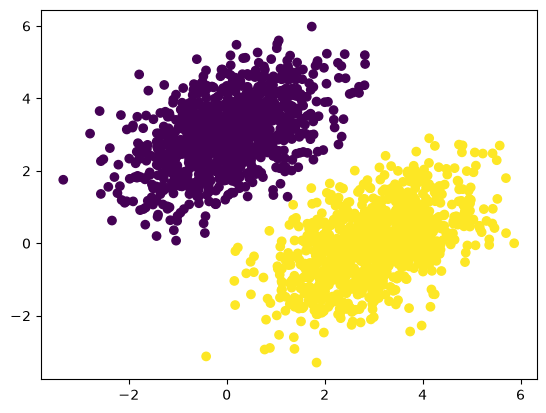

In [51]:
plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0])
plt.show()

In [52]:
# The inputs will be 2D points.
input_dim = 2
# The output predictions will be a single score per sample (close to 0
# if the sample is predicted to be in class 0, and close to 1 if the
# sample is predicted to be in class 1).
output_dim = 1
W = tf.Variable(initial_value=tf.random.uniform(shape=(input_dim, output_dim)))
b = tf.Variable(initial_value=tf.zeros(shape=(output_dim,)))

In [53]:
W

<tf.Variable 'Variable:0' shape=(2, 1) dtype=float32, numpy=
array([[0.48651707],
       [0.68542004]], dtype=float32)>

In [54]:
b

<tf.Variable 'Variable:0' shape=(1,) dtype=float32, numpy=array([0.], dtype=float32)>

In [55]:
def model(inputs, W, b):
    return tf.matmul(inputs, W) + b

In [56]:
def mean_squared_error(targets, predictions):
    # per_sample_losses will be a tensor with the same shape as targets
    # and predictions, containing per-sample loss scores.
    per_sample_losses = tf.square(targets - predictions)
    # We need to average these per-sample loss scores into a single
    # scalar loss value: reduce_mean does this.
    return tf.reduce_mean(per_sample_losses)

In [57]:
learning_rate = 0.1

# Wraps the function in a tf.function decorator to speed it up
@tf.function(jit_compile=True)
def training_step(inputs, targets, W, b):
    # Forward pass, inside of a gradient tape scope
    with tf.GradientTape() as tape:
        predictions = model(inputs, W, b)
        loss = mean_squared_error(predictions, targets)
    # Retrieves the gradient of the loss with regard to weights
    grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b])
    # Updates the weights
    W.assign_sub(grad_loss_wrt_W * learning_rate)
    b.assign_sub(grad_loss_wrt_b * learning_rate)
    return loss

In [58]:
for step in range(40):
    loss = training_step(inputs, targets, W, b)
    print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 3.2573
Loss at step 1: 0.4403
Loss at step 2: 0.1649
Loss at step 3: 0.1240
Loss at step 4: 0.1121
Loss at step 5: 0.1043
Loss at step 6: 0.0975
Loss at step 7: 0.0914
Loss at step 8: 0.0857
Loss at step 9: 0.0806
Loss at step 10: 0.0758
Loss at step 11: 0.0715
Loss at step 12: 0.0676
Loss at step 13: 0.0639
Loss at step 14: 0.0606
Loss at step 15: 0.0576
Loss at step 16: 0.0548
Loss at step 17: 0.0522
Loss at step 18: 0.0499
Loss at step 19: 0.0477
Loss at step 20: 0.0458
Loss at step 21: 0.0440
Loss at step 22: 0.0424
Loss at step 23: 0.0408
Loss at step 24: 0.0395
Loss at step 25: 0.0382
Loss at step 26: 0.0371
Loss at step 27: 0.0360
Loss at step 28: 0.0350
Loss at step 29: 0.0341
Loss at step 30: 0.0333
Loss at step 31: 0.0326
Loss at step 32: 0.0319
Loss at step 33: 0.0313
Loss at step 34: 0.0307
Loss at step 35: 0.0302
Loss at step 36: 0.0297
Loss at step 37: 0.0293
Loss at step 38: 0.0289
Loss at step 39: 0.0285


I0000 00:00:1793613611.949167   43180 service.cc:153] XLA service 0x56d0e90 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793613611.949190   43180 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793613612.090056   43180 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


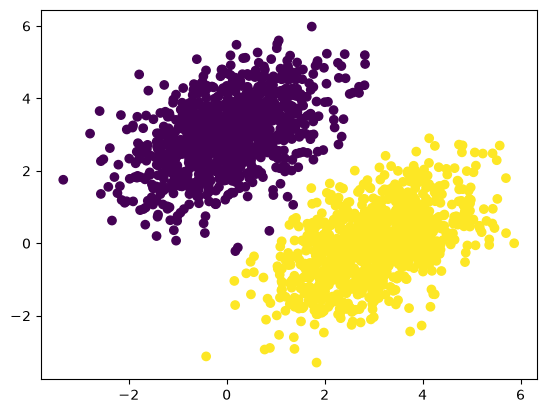

In [59]:
predictions = model(inputs, W, b)
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)
plt.show()

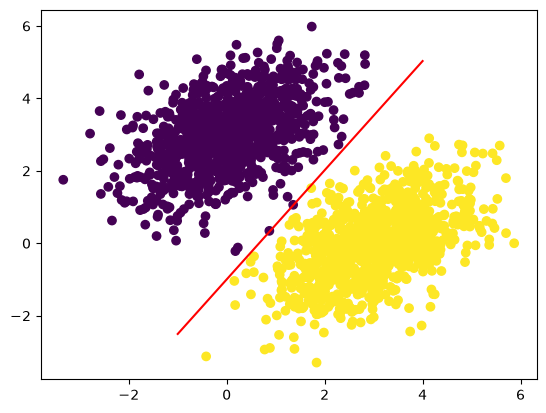

In [60]:
# Generates 100 regularly spaced numbers between -1 and 4, which we
# will use to plot our line
x = np.linspace(-1, 4, 100)
# This is our line's equation.
y = -W[0] / W[1] * x + (0.5 - b) / W[1]
# Plots our line (`"-r"` means "plot it as a red line")
plt.plot(x, y, "-r")
# Plots our model's predictions on the same plot
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)